# Studi Kasus Klasifikasi: Prediksi Gagal Bayar Kartu Kredit (Credit Default) pada Nasabah Bank

**Tugas Individu | Machine Learning**

Nama: [Afiq Purwantoro]
NIM: [2404010019]
Mata Kuliah: [Data Mining]

## 1. Permasalahan yang Dihadapi

### 1.1 Contoh Penerapan di Dunia Nyata
Bank dan penerbit kartu kredit menghadapi risiko kredit, yaitu risiko nasabah gagal membayar tagihan (*default*). Penelitian Yeh dan Lien (2009) memakai data nyata nasabah kartu kredit di Taiwan untuk membandingkan enam metode *data mining* dalam memprediksi gagal bayar. Data dari penelitian tersebut kemudian dipublikasikan di UCI Machine Learning Repository dan dipakai pada studi kasus ini.

Sumber penerapan nyata: Yeh, I. C., & Lien, C. H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications, 36*(2), 2473-2480.

### 1.2 Permasalahan
1. Gagal bayar menimbulkan kerugian finansial bagi bank dan menurunkan kualitas portofolio kredit.
2. Penilaian risiko secara manual sulit diterapkan secara konsisten pada puluhan ribu nasabah.
3. Pemberian limit kredit tanpa penilaian risiko yang baik dapat meningkatkan kredit macet.
4. Data bersifat tidak seimbang (nasabah gagal bayar lebih sedikit daripada yang membayar), sehingga akurasi saja bisa menyesatkan.

### 1.3 Tujuan
1. Membangun model klasifikasi untuk memprediksi apakah nasabah akan gagal bayar pada bulan berikutnya.
2. Membandingkan performa Logistic Regression dan Random Forest.
3. Mengidentifikasi fitur yang paling berpengaruh terhadap gagal bayar.

## 2. Metode Klasifikasi

### 2.1 Logistic Regression
Memodelkan probabilitas kelas dengan fungsi sigmoid terhadap kombinasi linear fitur, lalu mengubahnya menjadi kelas dengan *threshold* (umumnya 0,5).

**Alasan pemilihan:** sederhana, cepat, cocok sebagai *baseline*, dan koefisiennya mudah dijelaskan. Interpretabilitas penting di bidang keuangan karena keputusan kredit sering harus dapat dipertanggungjawabkan.

### 2.2 Random Forest
Metode *ensemble* yang membangun banyak *decision tree* pada sampel dan subset fitur yang berbeda, lalu menggabungkan prediksi dengan *voting* mayoritas.

**Alasan pemilihan:** mampu menangkap hubungan non-linear dan interaksi antar fitur (misalnya antara riwayat keterlambatan dan jumlah tagihan), lebih tahan *overfitting* dibanding satu pohon keputusan, dan menyediakan *feature importance*.

Kedua model memakai `class_weight='balanced'` untuk menangani ketidakseimbangan kelas.

## 3. Dataset

**Nama dataset:** Default of Credit Card Clients

**Sumber (data nyata, bukan data sintetis):** UCI Machine Learning Repository, disumbangkan oleh I-Cheng Yeh. Data berasal dari nasabah kartu kredit di Taiwan.
- Halaman dataset: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- Lisensi: Creative Commons Attribution 4.0 (CC BY 4.0)

**Ukuran:** 30.000 baris (nasabah), 23 fitur, dan 1 variabel target.

**Variabel target:** `DEFAULT` (1 = gagal bayar pada bulan berikutnya, 0 = tidak gagal bayar).

| Fitur | Keterangan |
|---|---|
| `LIMIT_BAL` | Jumlah kredit yang diberikan (dolar Taiwan), mencakup kredit individu dan keluarga |
| `SEX` | Jenis kelamin (1 = laki-laki, 2 = perempuan) |
| `EDUCATION` | Pendidikan (1 = pascasarjana, 2 = universitas, 3 = SMA, 4 = lainnya) |
| `MARRIAGE` | Status pernikahan (1 = menikah, 2 = lajang, 3 = lainnya) |
| `AGE` | Usia (tahun) |
| `PAY_0`, `PAY_2` - `PAY_6` | Status pembayaran bulanan (September sampai April 2005): -1 = tepat waktu, 1 = terlambat 1 bulan, 2 = terlambat 2 bulan, dan seterusnya |
| `BILL_AMT1` - `BILL_AMT6` | Jumlah tagihan bulanan (September sampai April 2005) |
| `PAY_AMT1` - `PAY_AMT6` | Jumlah pembayaran bulanan sebelumnya (September sampai April 2005) |

Catatan: nama kolom dalam notebook ini disesuaikan dengan dokumentasi dataset (X1 sampai X23 dan Y pada UCI).

## 4. Tahapan Penerapan
Tahapan: (1) import library dan load data, (2) EDA dan preprocessing, (3) pelatihan dan prediksi, (4) evaluasi.

### Langkah 1: Import Library dan Load Dataset

In [19]:
# Instalasi paket resmi UCI untuk mengambil dataset (hanya perlu sekali per sesi Colab)
!pip install -q ucimlrepo xlrd

In [20]:
import io, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
RANDOM_STATE = 42
print("Library berhasil di-import.")

Library berhasil di-import.


In [21]:
# Nama kolom sesuai urutan dokumentasi UCI (X1..X23, lalu target Y)
NAMA_KOLOM = (
    ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
     "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
    + ["DEFAULT"]
)

def muat_dataset():
    # Cara 1: paket resmi ucimlrepo (dataset id 350 = Default of Credit Card Clients)
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=350)
        data = pd.concat([ds.data.features, ds.data.targets], axis=1)
        print("Sumber data: paket ucimlrepo (UCI, id 350)")
        return data
    except Exception as e:
        print("ucimlrepo gagal:", e)

    # Cara 2 (cadangan): unduh berkas dari UCI secara langsung
    import requests
    url = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    nama_xls = [n for n in z.namelist() if n.lower().endswith(".xls")][0]
    data = pd.read_excel(z.open(nama_xls), header=1).iloc[:, 1:]  # buang kolom ID
    print("Sumber data: unduhan langsung UCI")
    return data

df = muat_dataset()
assert df.shape[1] == len(NAMA_KOLOM), f"Jumlah kolom tidak sesuai: {df.shape[1]}"
df.columns = NAMA_KOLOM

print("Ukuran dataset (baris, kolom):", df.shape)
df.head()

Sumber data: paket ucimlrepo (UCI, id 350)
Ukuran dataset (baris, kolom): (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Langkah 2: Exploratory Data Analysis (EDA) dan Data Preprocessing

In [22]:
df.info()
print("\nStatistik deskriptif:")
display(df.describe().T)
print("\nJumlah data duplikat:", df.duplicated().sum())
print("\nMissing value per kolom:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() > 0 else "Tidak ada missing value.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0



Jumlah data duplikat: 35

Missing value per kolom:
Tidak ada missing value.


DEFAULT
0    23364
1     6636
Name: count, dtype: int64

Proporsi (%):
DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64


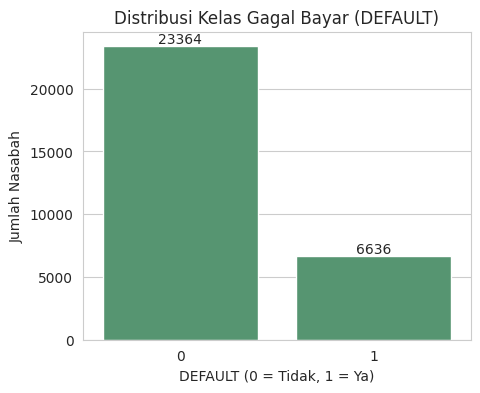

In [23]:
print(df["DEFAULT"].value_counts())
print("\nProporsi (%):")
print((df["DEFAULT"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="DEFAULT", color="#4C9F70")
plt.title("Distribusi Kelas Gagal Bayar (DEFAULT)")
plt.xlabel("DEFAULT (0 = Tidak, 1 = Ya)")
plt.ylabel("Jumlah Nasabah")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

**Pemeriksaan kategori.** Dokumentasi menyebut `EDUCATION` bernilai 1-4 dan `MARRIAGE` bernilai 1-3. Cell berikut memeriksa apakah data berisi nilai di luar dokumentasi.

In [24]:
for kolom in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"Nilai unik {kolom}:")
    print(df[kolom].value_counts().sort_index().to_string())
    print()

Nilai unik SEX:
SEX
1    11888
2    18112

Nilai unik EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51

Nilai unik MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323



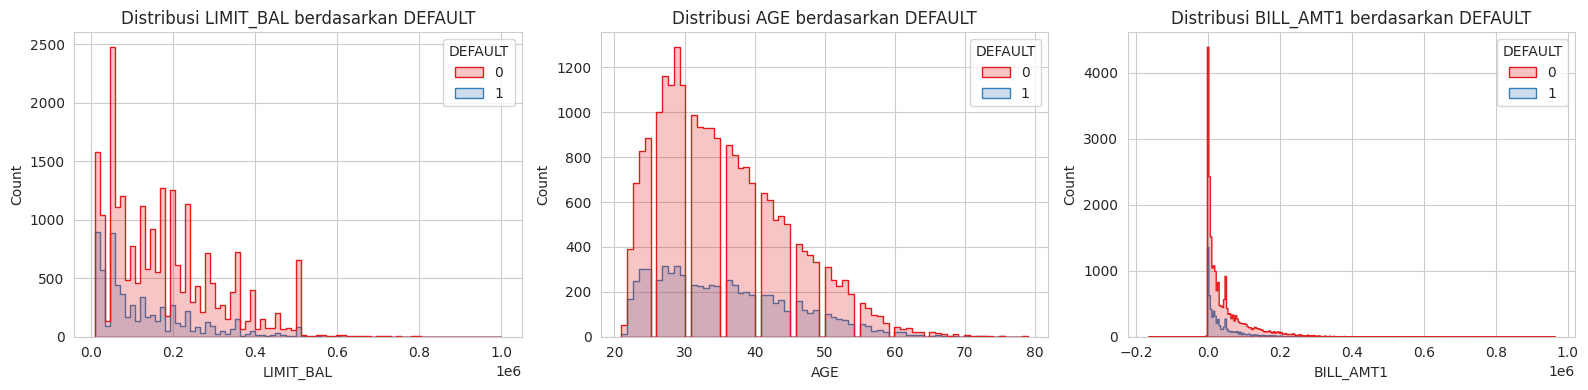

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["LIMIT_BAL", "AGE", "BILL_AMT1"]):
    sns.histplot(data=df, x=col, hue="DEFAULT", kde=False, ax=ax, palette="Set1", element="step")
    ax.set_title(f"Distribusi {col} berdasarkan DEFAULT")
plt.tight_layout()
plt.show()

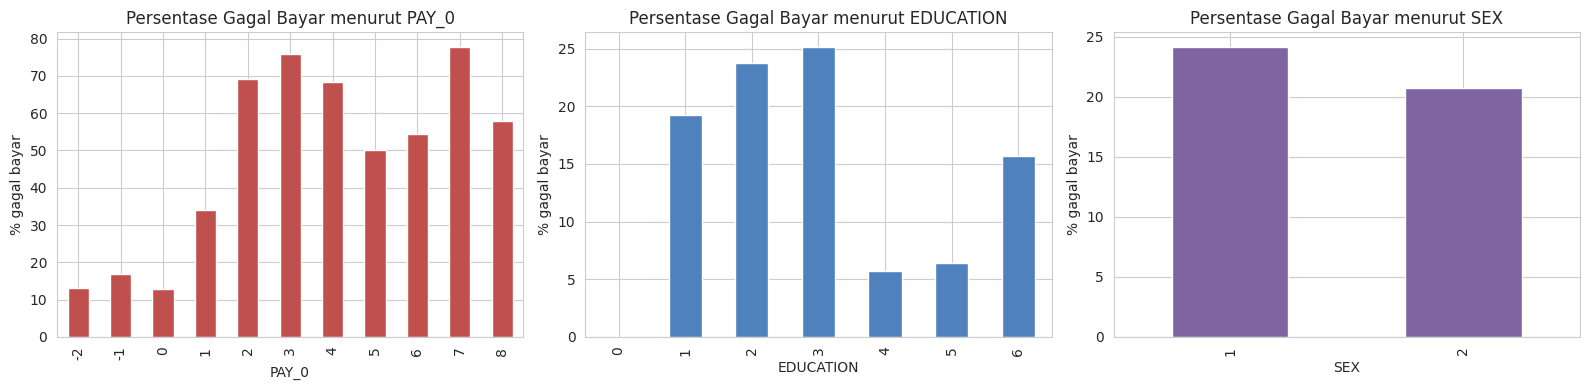

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Tingkat gagal bayar menurut status pembayaran bulan terakhir (PAY_0)
(df.groupby("PAY_0")["DEFAULT"].mean() * 100).plot(kind="bar", ax=axes[0], color="#C0504D")
axes[0].set_title("Persentase Gagal Bayar menurut PAY_0")
axes[0].set_ylabel("% gagal bayar")

# Tingkat gagal bayar menurut pendidikan
(df.groupby("EDUCATION")["DEFAULT"].mean() * 100).plot(kind="bar", ax=axes[1], color="#4F81BD")
axes[1].set_title("Persentase Gagal Bayar menurut EDUCATION")
axes[1].set_ylabel("% gagal bayar")

# Tingkat gagal bayar menurut jenis kelamin
(df.groupby("SEX")["DEFAULT"].mean() * 100).plot(kind="bar", ax=axes[2], color="#8064A2")
axes[2].set_title("Persentase Gagal Bayar menurut SEX")
axes[2].set_ylabel("% gagal bayar")

plt.tight_layout()
plt.show()

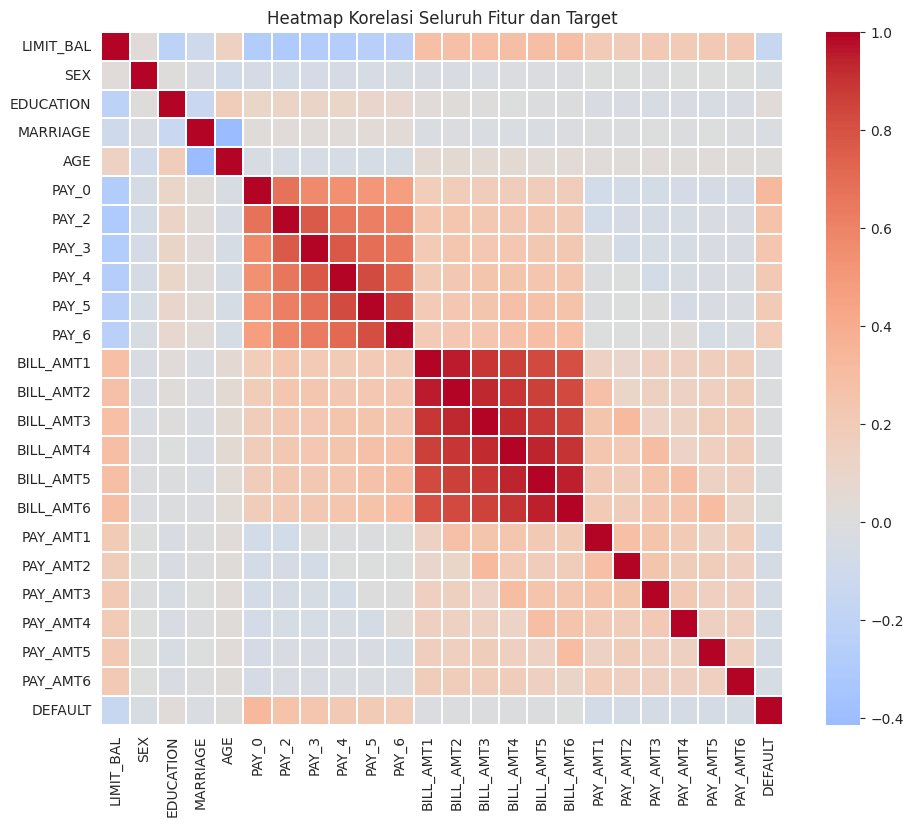

Korelasi tiap fitur dengan DEFAULT (terurut):
PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
EDUCATION    0.028
AGE          0.014
BILL_AMT6   -0.005
BILL_AMT5   -0.007
BILL_AMT4   -0.010
BILL_AMT3   -0.014
BILL_AMT2   -0.014
BILL_AMT1   -0.020
MARRIAGE    -0.024
SEX         -0.040
PAY_AMT6    -0.053
PAY_AMT5    -0.055
PAY_AMT3    -0.056
PAY_AMT4    -0.057
PAY_AMT2    -0.059
PAY_AMT1    -0.073
LIMIT_BAL   -0.154


In [27]:
plt.figure(figsize=(11, 9))
corr = df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Heatmap Korelasi Seluruh Fitur dan Target")
plt.show()

print("Korelasi tiap fitur dengan DEFAULT (terurut):")
print(corr["DEFAULT"].drop("DEFAULT").sort_values(ascending=False).round(3).to_string())

**Preprocessing.** Langkah yang dilakukan:
1. Nilai `EDUCATION` di luar 1-3 digabung ke kategori 4 (lainnya), dan nilai `MARRIAGE` di luar 1-2 digabung ke kategori 3 (lainnya).
2. Fitur dibagi menjadi numerik (di-*scaling*) dan kategorikal (*one-hot encoding*). Status pembayaran `PAY_*` diperlakukan sebagai fitur numerik karena bersifat berurutan.
3. Data dibagi 80:20 dengan stratifikasi.
4. Imputasi, scaling, dan encoding di-*fit* hanya pada data latih (di dalam *pipeline*) agar tidak terjadi *data leakage*.

In [28]:
df_clean = df.copy()

# Rapikan kategori di luar dokumentasi
df_clean.loc[~df_clean["EDUCATION"].isin([1, 2, 3]), "EDUCATION"] = 4
df_clean.loc[~df_clean["MARRIAGE"].isin([1, 2]), "MARRIAGE"] = 3

X = df_clean.drop(columns=["DEFAULT"])
y = df_clean["DEFAULT"].astype(int)

categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Fitur numerik    :", numeric_features)
print("Fitur kategorikal:", categorical_features)

# Split 80:20 dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("\nData latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi gagal bayar latih (%):", round(y_train.mean() * 100, 2))
print("Proporsi gagal bayar uji   (%):", round(y_test.mean() * 100, 2))

Fitur numerik    : ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Fitur kategorikal: ['SEX', 'EDUCATION', 'MARRIAGE']

Data latih: (24000, 23) | Data uji: (6000, 23)
Proporsi gagal bayar latih (%): 22.12
Proporsi gagal bayar uji   (%): 22.12


In [29]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3',
                                  'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1',
                                  'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
                                  'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
                                  'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4',
                                  'PAY_AMT5', 'PAY_AMT6']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['SEX', 'EDUCATION', 'MARRIAGE'])])

### Langkah 3: Pelatihan dan Prediksi Model

In [30]:
pipe_lr = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000,
                                 random_state=RANDOM_STATE))
])

pipe_rf = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=10,
                                     class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=-1))
])

pipe_lr.fit(X_train, y_train)
pipe_rf.fit(X_train, y_train)
print("Kedua model berhasil dilatih.")

Kedua model berhasil dilatih.


In [31]:
y_pred_lr = pipe_lr.predict(X_test)
y_pred_rf = pipe_rf.predict(X_test)
y_proba_lr = pipe_lr.predict_proba(X_test)[:, 1]
y_proba_rf = pipe_rf.predict_proba(X_test)[:, 1]

pd.DataFrame({
    "Aktual": y_test.values[:10],
    "Pred_LogReg": y_pred_lr[:10],
    "Pred_RandomForest": y_pred_rf[:10],
    "Prob_Default_RF": y_proba_rf[:10].round(3)
})

,Aktual,Pred_LogReg,Pred_RandomForest,Prob_Default_RF
0,0,0,0,0.337
1,0,0,0,0.346
2,0,0,0,0.378
3,1,0,0,0.330
4,0,0,0,0.135
5,0,0,1,0.599
6,0,0,0,0.260
7,0,0,0,0.141
8,0,0,0,0.280
9,0,0,0,0.262


In [32]:
# Validasi silang 5-fold pada data latih (metrik: F1 kelas gagal bayar)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_lr = cross_val_score(pipe_lr, X_train, y_train, cv=cv, scoring="f1")
cv_rf = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring="f1")

print(f"Logistic Regression - F1 CV: {cv_lr.mean():.4f} (+/- {cv_lr.std():.4f})")
print(f"Random Forest       - F1 CV: {cv_rf.mean():.4f} (+/- {cv_rf.std():.4f})")

Logistic Regression - F1 CV: 0.4811 (+/- 0.0117)
Random Forest       - F1 CV: 0.5457 (+/- 0.0062)


### Langkah 4: Evaluasi Performa
Evaluasi memakai *accuracy*, *classification report*, *confusion matrix*, dan ROC-AUC. Karena data tidak seimbang, fokus utama adalah recall, F1-score, dan ROC-AUC pada kelas gagal bayar.

In [33]:
target_names = ["Tidak Gagal Bayar (0)", "Gagal Bayar (1)"]

for nama, y_pred, y_proba in [("LOGISTIC REGRESSION", y_pred_lr, y_proba_lr),
                              ("RANDOM FOREST", y_pred_rf, y_proba_rf)]:
    print("=" * 60)
    print(nama)
    print("=" * 60)
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_proba), 4))
    print(classification_report(y_test, y_pred, target_names=target_names))

LOGISTIC REGRESSION
Accuracy : 0.6788
ROC-AUC  : 0.7104
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.87      0.69      0.77      4673
      Gagal Bayar (1)       0.37      0.63      0.46      1327

             accuracy                           0.68      6000
            macro avg       0.62      0.66      0.62      6000
         weighted avg       0.76      0.68      0.70      6000

RANDOM FOREST
Accuracy : 0.7837
ROC-AUC  : 0.7765
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.88      0.84      0.86      4673
      Gagal Bayar (1)       0.51      0.59      0.55      1327

             accuracy                           0.78      6000
            macro avg       0.69      0.71      0.70      6000
         weighted avg       0.80      0.78      0.79      6000



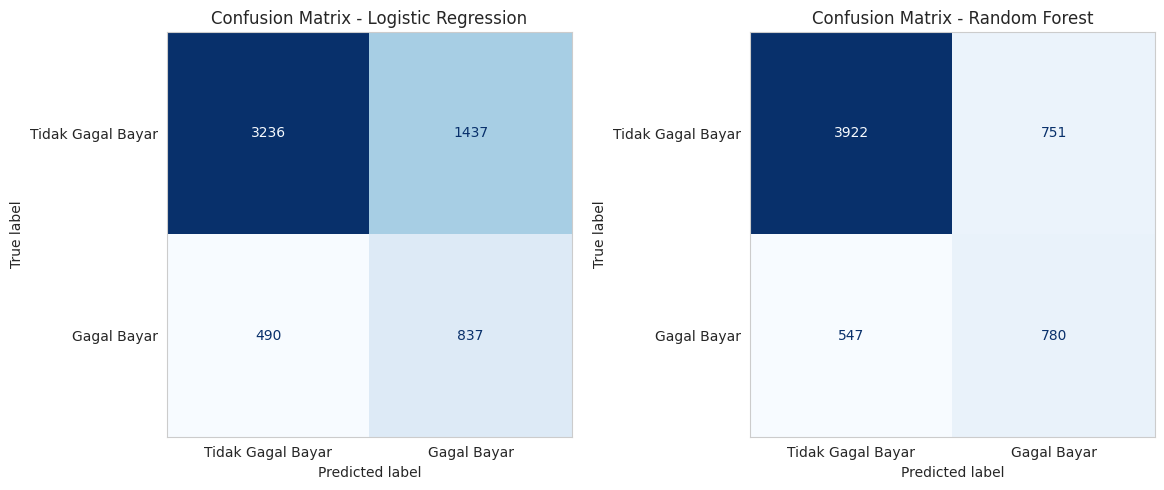

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nama, y_pred) in zip(axes, [("Logistic Regression", y_pred_lr),
                                      ("Random Forest", y_pred_rf)]):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Tidak Gagal Bayar", "Gagal Bayar"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Confusion Matrix - {nama}")
    ax.grid(False)

plt.tight_layout()
plt.show()

,Accuracy,Precision (Gagal Bayar),Recall (Gagal Bayar),F1-Score (Gagal Bayar),ROC-AUC
Model,,,,,
Logistic Regression,0.6788,0.3681,0.6307,0.4649,0.7104
Random Forest,0.7837,0.5095,0.5878,0.5458,0.7765


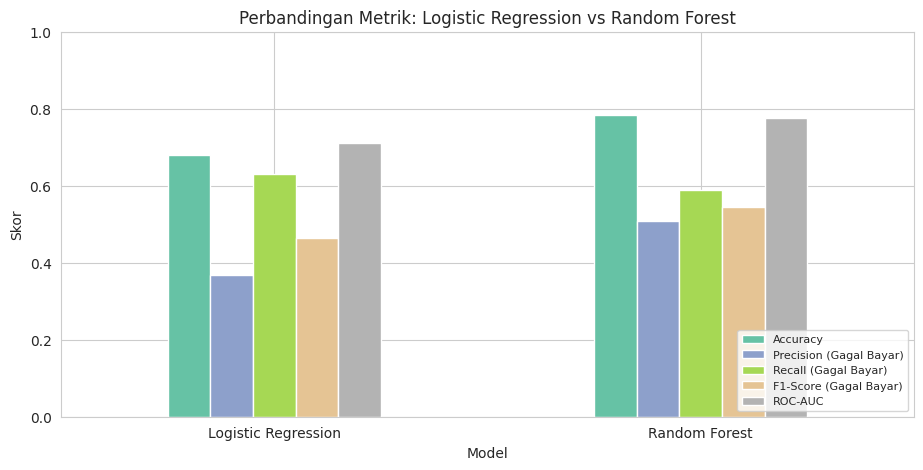

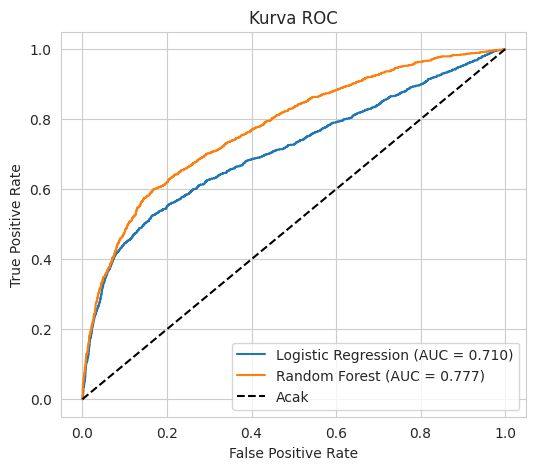

In [35]:
def ringkas_metrik(nama, y_true, y_pred, y_proba):
    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Gagal Bayar)": precision_score(y_true, y_pred),
        "Recall (Gagal Bayar)": recall_score(y_true, y_pred),
        "F1-Score (Gagal Bayar)": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba)
    }

tabel = pd.DataFrame([
    ringkas_metrik("Logistic Regression", y_test, y_pred_lr, y_proba_lr),
    ringkas_metrik("Random Forest", y_test, y_pred_rf, y_proba_rf)
]).set_index("Model").round(4)

display(tabel)

tabel.plot(kind="bar", figsize=(11, 5), colormap="Set2")
plt.title("Perbandingan Metrik: Logistic Regression vs Random Forest")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right", fontsize=8)
plt.show()

plt.figure(figsize=(6, 5))
for nama, proba in [("Logistic Regression", y_proba_lr), ("Random Forest", y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{nama} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC")
plt.legend()
plt.show()

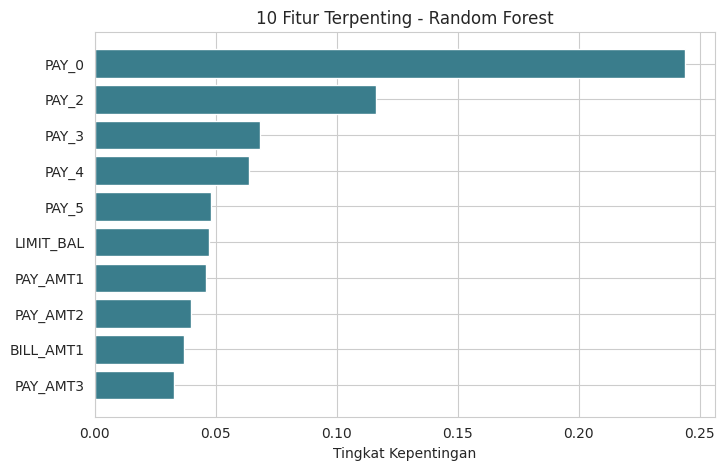

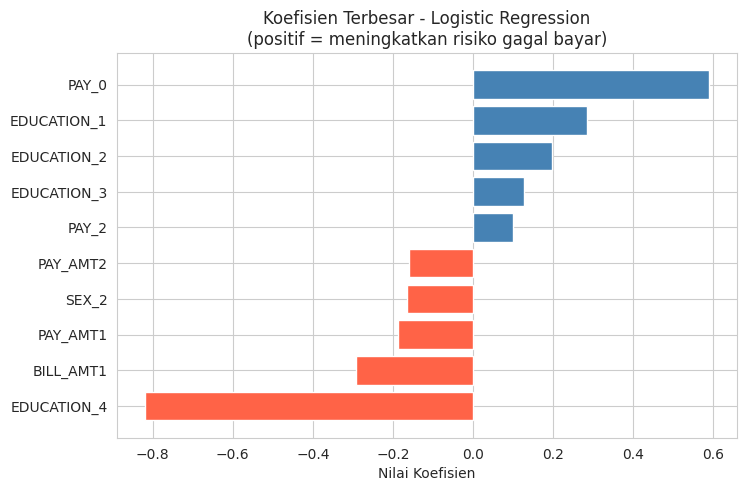

In [36]:
feature_names = pipe_rf.named_steps["preprocess"].get_feature_names_out()
feature_names = [f.replace("num__", "").replace("cat__", "") for f in feature_names]

# Random Forest: feature importance
fi = pd.Series(pipe_rf.named_steps["model"].feature_importances_,
               index=feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(fi.index[::-1], fi.values[::-1], color="#3A7D8C")
plt.title("10 Fitur Terpenting - Random Forest")
plt.xlabel("Tingkat Kepentingan")
plt.show()

# Logistic Regression: koefisien (fitur numerik sudah distandarisasi)
coef_series = pd.Series(pipe_lr.named_steps["model"].coef_[0], index=feature_names)
top_coef = pd.concat([coef_series.sort_values().head(5), coef_series.sort_values().tail(5)])

plt.figure(figsize=(8, 5))
colors = ["tomato" if v < 0 else "steelblue" for v in top_coef.values]
plt.barh(top_coef.index, top_coef.values, color=colors)
plt.title("Koefisien Terbesar - Logistic Regression\n(positif = meningkatkan risiko gagal bayar)")
plt.xlabel("Nilai Koefisien")
plt.show()

## 5. Hasil dan Manfaat

### 5.1 Interpretasi Hasil

**a. Logistic Regression.** Accuracy **[isi]**, recall gagal bayar **[isi]**, precision gagal bayar **[isi]**, dan ROC-AUC **[isi]**. Recall berarti dari seluruh nasabah yang benar-benar gagal bayar, model berhasil mengenali sekitar **[isi]%**. Precision berarti dari seluruh nasabah yang diprediksi gagal bayar, sekitar **[isi]%** benar-benar gagal bayar.

**b. Random Forest.** Accuracy **[isi]**, recall gagal bayar **[isi]**, precision gagal bayar **[isi]**, dan ROC-AUC **[isi]**. [Bandingkan dengan Logistic Regression: lebih tinggi atau lebih rendah, pada metrik apa.]

**c. Perbandingan.** Pada data tidak seimbang, accuracy saja dapat menyesatkan, karena model yang selalu menebak "tidak gagal bayar" pun mendapat akurasi sebesar proporsi kelas mayoritas (**[isi dari Cell distribusi target]%**). Karena itu, recall, F1-score, dan ROC-AUC kelas gagal bayar dijadikan acuan utama. Berdasarkan hasil di atas, model **[nama model]** lebih unggul karena **[alasan sesuai angka Anda]**. Pilihan akhir juga bergantung pada kebutuhan: interpretabilitas (Logistic Regression) atau kemampuan menangkap pola kompleks (Random Forest).

**d. Faktor berpengaruh.** Berdasarkan feature importance dan koefisien, fitur **[isi dari grafik]** tampak paling berpengaruh. Hal ini sejalan dengan hasil EDA yang menunjukkan **[isi temuan dari grafik EDA, misalnya hubungan PAY_0 dengan persentase gagal bayar]**.

**e. Keterbatasan.**
- Hanya menggunakan satu dataset dari satu wilayah dan satu periode (2005), sehingga belum tentu mewakili kondisi nasabah di tempat dan waktu lain.
- *Threshold* masih default (0,5) dan belum disesuaikan dengan biaya kesalahan prediksi (menolak nasabah baik versus meloloskan nasabah yang gagal bayar).
- Hiperparameter belum dioptimasi (misalnya dengan `GridSearchCV`).
- Hubungan antara fitur dan gagal bayar bersifat asosiatif, bukan sebab-akibat.
- Penggunaan atribut demografis seperti jenis kelamin dalam keputusan kredit nyata perlu dikaji dari sisi etika dan regulasi.

### 5.2 Manfaat Praktis bagi Industri/Bisnis
1. **Penilaian risiko kredit:** bank dapat memberi skor risiko gagal bayar pada setiap nasabah sebagai bahan pertimbangan persetujuan dan penentuan limit kredit.
2. **Pengurangan kredit macet:** nasabah berisiko tinggi dapat dipantau lebih awal, misalnya dengan pengingat tagihan atau restrukturisasi sebelum menunggak.
3. **Efisiensi operasional:** penilaian otomatis mengurangi beban analisis manual pada ribuan nasabah.
4. **Keputusan berbasis data:** fitur berpengaruh (misalnya riwayat keterlambatan pembayaran) membantu merancang kebijakan kredit dan strategi penagihan.
5. **Skalabilitas:** model dapat dijalankan berkala pada data nasabah terbaru untuk pemantauan risiko portofolio.

## 6. Daftar Referensi
*(Format APA edisi 7)*

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., ... Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357-362. https://doi.org/10.1038/s41586-020-2649-2

Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3rd ed.). John Wiley & Sons.

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61. https://doi.org/10.25080/Majora-92bf1922-00a

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021

Yeh, I. (2009). *Default of credit card clients* [Data set]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients

Yeh, I. C., & Lien, C. H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications, 36*(2), 2473-2480.